# 07 · The improved model against the deployed one

**Question:** with the changes of notebooks 04–06, how much better does the risk model rank and allocate the next window's loss than the deployed model (notebook 03) and Verra's benchmark?

| Model | Predictors | Trained on | Risk map covers |
|---|---|---|---|
| VT0007 benchmark | Distance from non-forest (cells under half forest) | – | Every cell with forest |
| Deployed model (platform) | The deployed eleven, yearly layers at their latest year, distance to prior loss | The platform's half-cell masks | Cells at least half forest |
| Improved model, half-cell masks | The improved model's 16, all at the window's start (notebook 05) | The platform's half-cell masks | Cells at least half forest |
| Improved model, trained on the shares | Same | Cells drawn in proportion to their forest lost and kept (notebook 04) | Every cell with forest |

The third row separates the two changes: the predictors alone, then the training on the shares. All are one national model (notebook 06), scored as in notebook 03: AUC over the 30 m forest pixels (mean of three seeds) and Verra's fit and prediction tests (first seed). Results are saved in `outputs/runs/`; set `RERUN = True` to compute them again (about 15 minutes per window).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "scripts"))
import model as MM
import verra as V

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = HERE.parent / "outputs" / "summary"
RERUN = False
runs = [MM.cached(V.split_name(s), lambda s=s: V.run_split(s), rerun=RERUN) for s in MM.SPLITS]

## 1 · Each window

In [2]:
rows = []
for run in runs:
    bench = run["models"]["benchmark"]
    for key, r in run["models"].items():
        rows.append({"Window": run["split"], "Model": V.LABELS[key],
                     "AUC (30 m pixels)": np.mean(r["aucs"]) if "aucs" in r else np.nan,
                     "Fit MedAE (ha)": r["fit_medae_ha"], "Prediction MedAE (ha)": r["prediction_medae_ha"],
                     "Beats the benchmark on both tests": "–" if key == "benchmark" else
                         ("yes" if r["fit_medae_ha"] < bench["fit_medae_ha"] and r["prediction_medae_ha"] < bench["prediction_medae_ha"] else "no"),
                     "Next loss in forest without a risk value (%)": 100 * r["loss_without_class"]})
results = pd.DataFrame(rows)
results.round(4).to_csv(OUT / "07_improved_vs_deployed.csv", index=False)
results.set_index(["Window", "Model"]).round(3)

AUC (30 m pixels)  \
Window                Model                                                           
2014–2016 → 2017–2019 VT0007 benchmark (distance to edge)                     0.694   
                      Deployed model, half-cell masks (platform)              0.717   
                      Improved model, half-cell masks                         0.722   
                      Improved model, weighted by the shares                  0.758   
2017–2019 → 2020–2022 VT0007 benchmark (distance to edge)                     0.673   
                      Deployed model, half-cell masks (platform)              0.681   
                      Improved model, half-cell masks                         0.696   
                      Improved model, weighted by the shares                  0.764   
2019–2021 → 2022–2024 VT0007 benchmark (distance to edge)                     0.638   
                      Deployed model, half-cell masks (platform)              0.631   
                      Improved model, half-cell masks                         0.646   
                      Improved model, weighted by the shares                  0.738   

                                                                  Fit MedAE (ha)  \
Window                Model                                                        
2014–2016 → 2017–2019 VT0007 benchmark (distance to edge)                251.760   
                      Deployed model, half-cell masks (platform)         129.938   
                      Improved model, half-cell masks                    110.379   
                      Improved model, weighted by the shares              91.114   
2017–2019 → 2020–2022 VT0007 benchmark (distance to edge)                385.399   
                      Deployed model, half-cell masks (platform)         185.083   
                      Improved model, half-cell masks                    150.341   
                      Improved model, weighted by the shares             141.726   
2019–2021 → 2022–2024 VT0007 benchmark (distance to edge)                422.414   
                      Deployed model, half-cell masks (platform)         156.374   
                      Improved model, half-cell masks                    161.775   
                      Improved model, weighted by the shares             120.199   

                                                                  Prediction MedAE (ha)  \
Window                Model                                                               
2014–2016 → 2017–2019 VT0007 benchmark (distance to edge)                       445.637   
                      Deployed model, half-cell masks (platform)                278.241   
                      Improved model, half-cell masks                           172.086   
                      Improved model, weighted by the shares                    230.356   
2017–2019 → 2020–2022 VT0007 benchmark (distance to edge)                       376.290   
                      Deployed model, half-cell masks (platform)                216.335   
                      Improved model, half-cell masks                           234.160   
                      Improved model, weighted by the shares                    173.387   
2019–2021 → 2022–2024 VT0007 benchmark (distance to edge)                       297.709   
                      Deployed model, half-cell masks (platform)                213.474   
                      Improved model, half-cell masks                           199.888   
                      Improved model, weighted by the shares                    154.909   

                                                                 Beats the benchmark on both tests  \
Window                Model                                                                          
2014–2016 → 2017–2019 VT0007 benchmark (distance to edge)                                        –   
                      Deployed model, half-cell masks (platform)                         

**Reading:**

* **Every model beats the benchmark on both of Verra's tests in every window.**
* **The improved model trained on the shares has the best AUC in every window (0.738–0.764) and the best fit test in every window.** On the prediction test it is best in the last two windows. In the first, the improved model with half-cell masks does better (172 ha against 230). Verra's errors move by 10–30 ha with the seed alone (notebook 05), so a single window's difference of that size decides nothing.
* **The half-cell masks leave 10–20 % of the next loss in forest without a risk value**, whatever the predictors. That is what holds the two half-cell models at an AUC of 0.63–0.72.

## 2 · Mean of the three windows

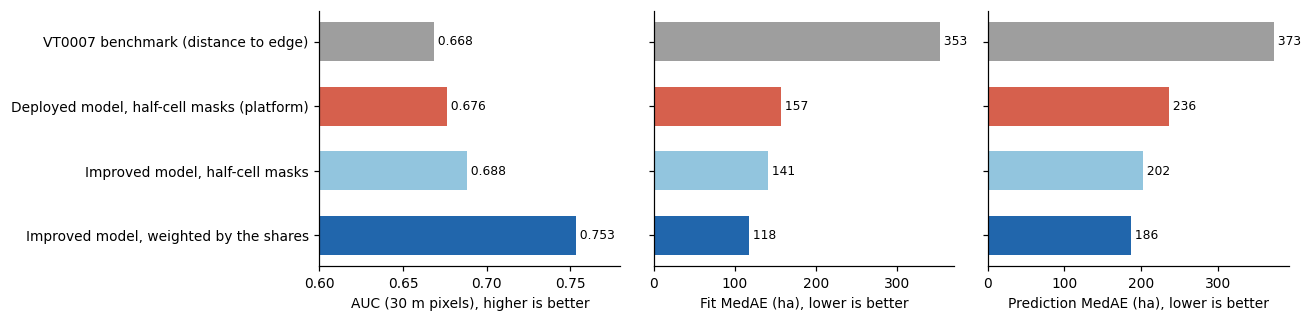

,AUC (30 m pixels),Fit MedAE (ha),Prediction MedAE (ha),Windows beating the benchmark
Model,,,,
VT0007 benchmark (distance to edge),0.668,353.191,373.212,NaN
"Deployed model, half-cell masks (platform)",0.676,157.131,236.017,3.0
"Improved model, half-cell masks",0.688,140.832,202.045,3.0
"Improved model, weighted by the shares",0.753,117.680,186.217,3.0


In [3]:
mean = results.groupby("Model", sort=False).agg(**{
    "AUC (30 m pixels)": ("AUC (30 m pixels)", "mean"), "Fit MedAE (ha)": ("Fit MedAE (ha)", "mean"),
    "Prediction MedAE (ha)": ("Prediction MedAE (ha)", "mean"),
    "Windows beating the benchmark": ("Beats the benchmark on both tests", lambda v: int((v == "yes").sum()))})
mean.loc[V.LABELS["benchmark"], "Windows beating the benchmark"] = np.nan
mean.round(3).to_csv(OUT / "07_improved_vs_deployed_mean.csv")

order = list(V.LABELS.values())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.0), sharey=True)
for ax, column, better in zip(axes, ["AUC (30 m pixels)", "Fit MedAE (ha)", "Prediction MedAE (ha)"], ["higher", "lower", "lower"]):
    values = mean.loc[order, column]
    ax.barh(np.arange(len(order)), values, color=["#9e9e9e", "#d6604d", "#92c5de", "#2166ac"], height=0.6)
    for y, v in enumerate(values):
        ax.text(v, y, f" {v:.3f}" if "AUC" in column else f" {v:.0f}", va="center", fontsize=8)
    ax.set_yticks(np.arange(len(order)), order)
    ax.set_xlabel(f"{column}, {better} is better")
    if "AUC" in column:
        ax.set_xlim(0.6, 0.78)
axes[0].invert_yaxis()
plt.tight_layout(); plt.show()
mean.round(3)

**Reading:**

* **Each change helps:**
  * the improved predictors, still on the half-cell masks: AUC 0.676 → 0.688, fit 157 → 141 ha, prediction 236 → 202 ha;
  * then training on the shares: AUC → 0.753, fit → 118 ha, prediction → 186 ha.
* **The predictors mostly lower Verra's errors; the training on the shares mostly raises the AUC**, because the whole forest gets a risk value.
* **Against the deployed model, the improved model has an AUC 0.077 higher, a fit error 25 % lower and a prediction error 21 % lower.** Against the benchmark: fit error 67 % lower, prediction error 50 % lower.

## 3 · What the models rely on

Random-forest importance, first seed, mean of the three windows: the six largest of each model.

In [4]:
imp = {}
for key in ("deployed_half", "improved_weighted"):
    m = pd.DataFrame([run["models"][key]["importance"] for run in runs]).mean().sort_values(ascending=False)
    imp[V.LABELS[key]] = [f"{name} ({value:.2f})" for name, value in m.head(6).items()]
pd.DataFrame(imp, index=range(1, 7))

,"Deployed model, half-cell masks (platform)","Improved model, weighted by the shares"
1,Land-surface temperature (0.16),Recent loss rate around the cell (5 km) (0.23)
2,Distance to prior loss (0.12),Land-surface temperature (0.10)
3,Precipitation (0.11),Precipitation (1991–2020 normal) (0.07)
4,Elevation (0.10),Distance to built-up area (0.06)
5,Soil moisture (0.09),Soil moisture (0.06)
6,Slope (0.08),Distance to recent loss (0.06)


**Reading:** the deployed model relies most on land-surface temperature, the distance to prior loss and rainfall, with the yearly layers read at 2024. The improved model relies on the local loss rate first (0.23), then temperature and the rainfall normal, all measured at the window's start.

## 4 · What this means

* **The improved model beats the deployed one on every score:** AUC 0.753 against 0.676, Verra's fit error 118 against 157 ha, prediction error 186 against 236 ha. It beats the benchmark on both tests in every window.
* **Training on the shares needs no new data:** the platform already computes them.
* **The changes for the platform** are in the README, "Decisions for the team": train on the shares (notebook 04), the improved predictors at the window's start (notebook 05), one national model (notebook 06), Verra's tests in the validation (notebook 03).
* **Next, notebook 08:** the improved model against other tools.